# Exploratory analysis with visualization

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
PAL = {0: "#C8452F", 1: "#1F7A6D"}


def scatter(x, y, name, xlabel, ylabel):
    g = sns.catplot(x=x, y=y, hue="Class", data=df, aspect=3.2, height=3.4, palette=PAL, s=38, native_scale=True)
    g.set_axis_labels(xlabel, ylabel, fontsize=13)
    g.savefig(f"images/{name}.png", dpi=170, bbox_inches="tight")
    plt.show()


print(df.shape)

(90, 18)


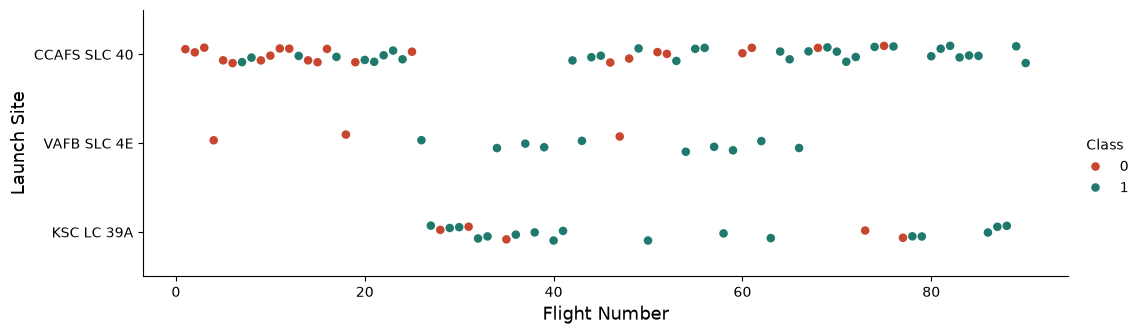

In [2]:
scatter("FlightNumber", "LaunchSite", "flight_site", "Flight Number", "Launch Site")

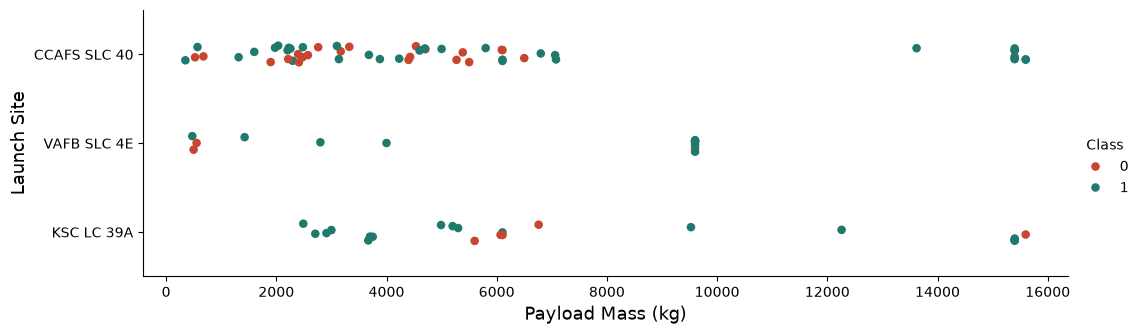

In [3]:
scatter("PayloadMass", "LaunchSite", "payload_site", "Payload Mass (kg)", "Launch Site")

,Orbit,mean,count
0,ES-L1,1.000000,1
1,GEO,1.000000,1
2,HEO,1.000000,1
3,SSO,1.000000,5
4,VLEO,0.857143,14
5,LEO,0.714286,7
6,PO,0.666667,9
7,MEO,0.666667,3
8,ISS,0.619048,21
9,GTO,0.518519,27


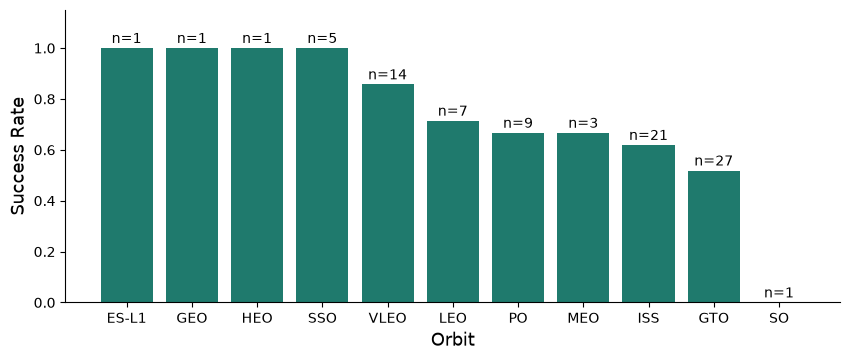

In [4]:
orbit = df.groupby("Orbit")["Class"].agg(["mean", "count"]).sort_values("mean", ascending=False).reset_index()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(orbit["Orbit"], orbit["mean"], color="#1F7A6D")
for i, r in orbit.iterrows():
    ax.text(i, r["mean"] + 0.02, f"n={r['count']}", ha="center", fontsize=10)
ax.set_ylim(0, 1.15)
ax.set_xlabel("Orbit", fontsize=13)
ax.set_ylabel("Success Rate", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("images/orbit_success.png", dpi=170, bbox_inches="tight")
orbit

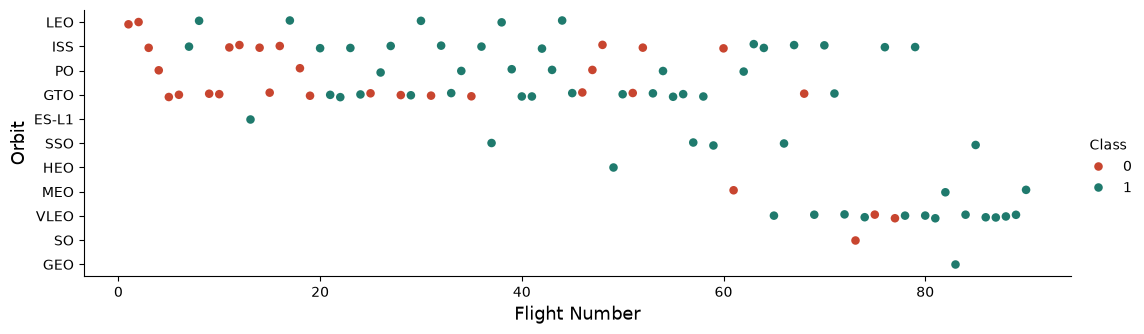

In [5]:
scatter("FlightNumber", "Orbit", "flight_orbit", "Flight Number", "Orbit")

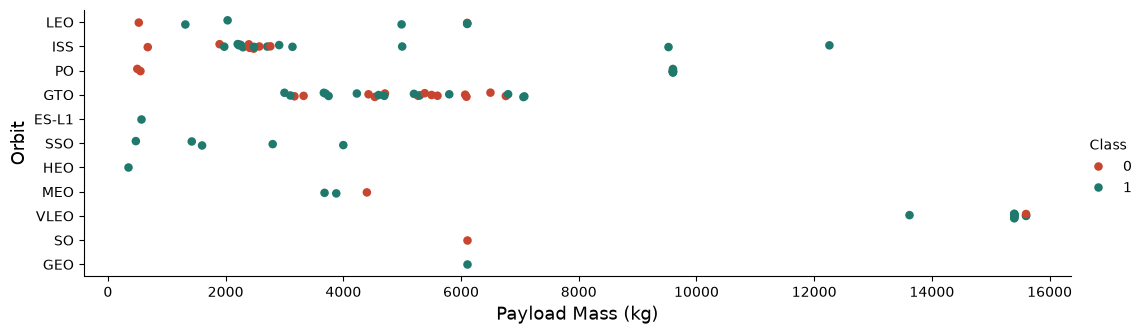

In [6]:
scatter("PayloadMass", "Orbit", "payload_orbit", "Payload Mass (kg)", "Orbit")

,Year,mean,count
0,2010,0.000000,1
1,2012,0.000000,1
2,2013,0.000000,3
3,2014,0.333333,6
4,2015,0.333333,6
5,2016,0.625000,8
6,2017,0.833333,18
7,2018,0.611111,18
8,2019,0.900000,10
9,2020,0.842105,19


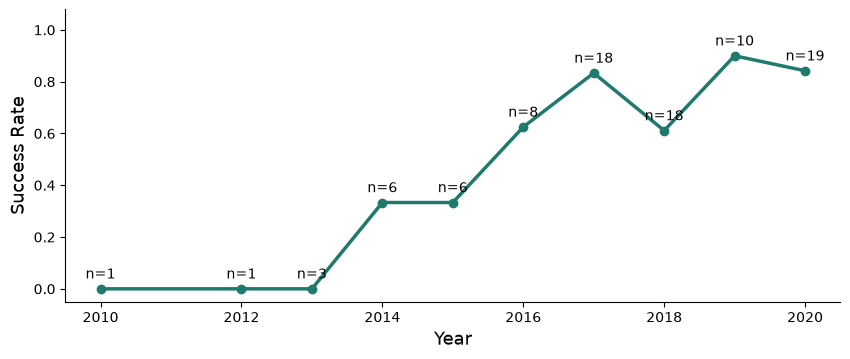

In [7]:
year = df["Date"].str[:4].astype(int).rename("Year")
yearly = df.groupby(year)["Class"].agg(["mean", "count"]).reset_index()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(yearly["Year"], yearly["mean"], marker="o", color="#1F7A6D", lw=2.5)
for _, r in yearly.iterrows():
    ax.text(r["Year"], r["mean"] + 0.04, f"n={int(r['count'])}", ha="center", fontsize=10)
ax.set_ylim(-0.05, 1.08)
ax.set_xlabel("Year", fontsize=13)
ax.set_ylabel("Success Rate", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("images/yearly_trend.png", dpi=170, bbox_inches="tight")
yearly

In [8]:
site = df.groupby("LaunchSite")["Class"].agg(["mean", "count"])
payload = df.assign(Heavy=df["PayloadMass"] > 8000).groupby("Heavy")["Class"].agg(["mean", "count"])
era = df.assign(Late=df["FlightNumber"] > 45, Heavy=df["PayloadMass"] > 8000).groupby(["Late", "Heavy"])["Class"].agg(["mean", "count"])
print(site, payload, era, sep="\n\n")

                  mean  count
LaunchSite                   
CCAFS SLC 40  0.600000     55
KSC LC 39A    0.772727     22
VAFB SLC 4E   0.769231     13

           mean  count
Heavy                 
False  0.597015     67
True   0.869565     23

                 mean  count
Late  Heavy                 
False False  0.536585     41
      True   1.000000      4
True  False  0.692308     26
      True   0.842105     19
